# <span style="color:green"> Laboratorio di Simulazione Numerica </span>
## <span style="color:orange"> Tommaso Cardano Chiezzi </span>

# Esercizio 12.1 — Deep Neural Network (DNN)

## Obiettivo

L'obiettivo è addestrare una rete neurale profonda per riconoscere
le cifre manoscritte del dataset MNIST.

Il problema è una classificazione supervisionata con 10 classi,
corrispondenti alle cifre da 0 a 9.

Verranno confrontati tre ottimizzatori:
**SGD, Adam e RMSprop**, mantenendo invariata l'architettura
della rete neurale.

Le prestazioni saranno valutate attraverso:
- Accuracy: frazione di classificazioni corrette.
- Loss: funzione di costo categorical cross-entropy.

Il confronto comprenderà l'andamento delle metriche
durante il training e la validation.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

# Seed per rendere gli esperimenti più riproducibili
SEED = 0
keras.utils.set_random_seed(SEED)

## 1. Caricamento del dataset MNIST

Il dataset MNIST contiene 70.000 immagini di cifre manoscritte,
suddivise in:

- 60.000 immagini di training.
- 10.000 immagini di test.

Ogni immagine è rappresentata da una matrice di 28 × 28 pixel,
in scala di grigi.

L'intensità di ciascun pixel assume valori compresi tra 0 e 255.

Poiché utilizziamo una DNN composta da layer Dense,
ogni immagine verrà trasformata in un vettore di 784 elementi.

Training: (60000, 28, 28)
Test: (10000, 28, 28)


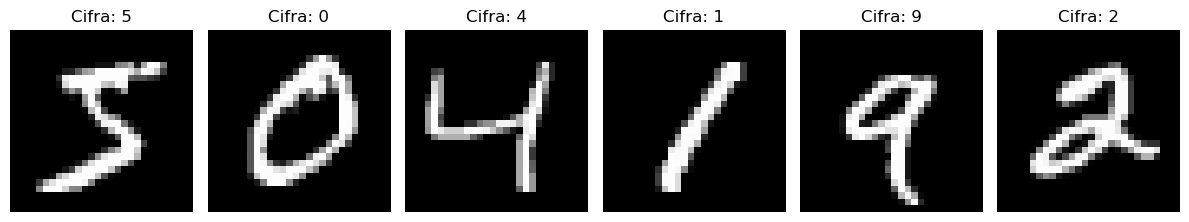

In [4]:
# Dimensioni delle immagini e numero di classi
img_rows, img_cols = 28, 28
num_classes = 10

# Caricamento automatico del dataset MNIST
(X_train_raw, y_train), (X_test_raw, y_test) = keras.datasets.mnist.load_data()

# Dimensioni originali del dataset
print("Training:", X_train_raw.shape)
print("Test:", X_test_raw.shape)

# Visualizzazione di alcune cifre manoscritte
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    ax.imshow(X_train_raw[i], cmap="gray")
    ax.set_title(f"Cifra: {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2. Preprocessing dei dati
### Normalizzazione

I valori dei pixel vengono divisi per 255:

$$
x_{\mathrm{norm}} = \frac{x}{255}
$$

In questo modo ogni pixel assume valori nell'intervallo [0,1].

### Flatten delle immagini

Ogni immagine viene trasformata in un vettore:

$$
28 \times 28 \longrightarrow 784
$$

### One-hot encoding

Le etichette vengono convertite in vettori di 10 componenti.

Ad esempio, la cifra 3 diventa:

$$
[0,0,0,1,0,0,0,0,0,0]
$$

### Suddivisione dei dati

Per confrontare correttamente gli ottimizzatori vengono utilizzati
54.000 immagini per il training, 6.000 per la validation
e 10.000 per il test finale.

In [5]:
# Normalizzazione delle immagini nell'intervallo [0, 1]
X_train_images = X_train_raw.astype("float32") / 255.0
X_test_images = X_test_raw.astype("float32") / 255.0

# Conversione delle immagini in vettori di 784 elementi
X_train = X_train_images.reshape(-1, img_rows * img_cols)
X_test = X_test_images.reshape(-1, img_rows * img_cols)

# Conversione delle etichette in one-hot encoding
Y_train = keras.utils.to_categorical(y_train, num_classes)
Y_test = keras.utils.to_categorical(y_test, num_classes)

# Separazione tra training e validation
n_val = 6000

X_fit = X_train[:-n_val]
Y_fit = Y_train[:-n_val]

X_val = X_train[-n_val:]
Y_val = Y_train[-n_val:]

# Verifica delle dimensioni
print("X_fit:", X_fit.shape)
print("Y_fit:", Y_fit.shape)

print("X_val:", X_val.shape)
print("Y_val:", Y_val.shape)

print("X_test:", X_test.shape)
print("Y_test:", Y_test.shape)

# Esempio di etichetta convertita
print("\nEtichetta originale:", y_train[0])
print("One-hot encoding:", Y_train[0])

X_fit: (54000, 784)
Y_fit: (54000, 10)
X_val: (6000, 784)
Y_val: (6000, 10)
X_test: (10000, 784)
Y_test: (10000, 10)

Etichetta originale: 5
One-hot encoding: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## 3. Architettura della Deep Neural Network

La rete neurale è composta da:

- Un layer di input con 784 componenti.
- Un layer Dense con 400 neuroni e attivazione ReLU.
- Un layer Dense con 100 neuroni e attivazione ReLU.
- Un layer Dropout con probabilità 0.5.
- Un layer di output con 10 neuroni e attivazione Softmax.

### Funzione ReLU

$$
f(x)=\max(0,x)
$$

Introduce non linearità nella rete neurale.

### Dropout

Durante il training il dropout disattiva casualmente
il 50% delle unità del layer precedente, riducendo
il rischio di overfitting.

### Funzione Softmax

$$
p_i=\frac{e^{z_i}}{\sum_{j=1}^{10}e^{z_j}}
$$

Converte i valori di output in probabilità
associate alle 10 classi.

In [6]:
def create_DNN():

    # Creazione della rete neurale sequenziale
    model = keras.Sequential([

        # Layer di input: 28 x 28 = 784 pixel
        keras.Input(shape=(img_rows * img_cols,)),

        # Primo layer nascosto
        layers.Dense(400, activation="relu"),

        # Secondo layer nascosto
        layers.Dense(100, activation="relu"),

        # Dropout per ridurre l'overfitting
        layers.Dropout(0.5),

        # Layer di output: 10 probabilità
        layers.Dense(num_classes, activation="softmax")
    ])

    return model


# Creazione del modello
model_example = create_DNN()

# Visualizzazione dell'architettura
model_example.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 400)                 │         314,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 100)                 │          40,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 355,110 (1.35 MB)

 Trainable params: 355,110 (1.35 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Training and Early Stopping

Per confrontare le prestazioni dei tre ottimizzatori, vengono
addestrate tre DNN con la stessa architettura e gli stessi
pesi iniziali.

Gli ottimizzatori considerati sono:
- SGD (Stochastic Gradient Descent)
- Adam (Adaptive Moment Estimation)
- RMSprop (Root Mean Square Propagation)


La funzione di costo adottata è la **categorical cross-entropy**,
appropriata per problemi di classificazione multiclasse:

$$
L=-\frac{1}{N}\sum_{i=1}^{N}\sum_{k=1}^{10}
y_{ik}\log(p_{ik})
$$

dove $y_{ik}$ rappresenta l'etichetta reale e $p_{ik}$ la
probabilità predetta per la classe $k$.
### Early Stopping


L'Early Stopping è una tecnica di regolarizzazione che permette
di interrompere l'addestramento quando il modello non mostra
ulteriori miglioramenti sulla validation loss.

In questo esercizio utilizziamo:

- Un massimo di 25 epoche.
- Patience = 4 epoche.
- Monitoraggio della validation loss.
- Ripristino dei pesi migliori.

Questa procedura limita il rischio di overfitting e permette
a ciascun ottimizzatore di arrestarsi in un punto differente.

Il confronto finale verrà effettuato sui modelli ripristinati
all'epoca con la migliore validation loss.

In [12]:
# Parametri dell'addestramento
batch_size = 32
max_epochs = 25
patience = 4

# Ottimizzatori e rispettivi learning rate
optimizer_configs = {
    "SGD": lambda: keras.optimizers.SGD(learning_rate=0.01),
    "Adam": lambda: keras.optimizers.Adam(learning_rate=0.001),
    "RMSprop": lambda: keras.optimizers.RMSprop(learning_rate=0.001)
}

# Pesi iniziali identici per tutte le reti
initial_weights = model_example.get_weights()

# Dizionari per salvare modelli e risultati
models = {}
histories = {}
training_info = {}

# Addestramento delle tre reti
for name, optimizer_factory in optimizer_configs.items():

    print(f"\n{'=' * 50}")
    print(f"Training con ottimizzatore: {name}")
    print(f"{'=' * 50}")

    # Ripristino del seed
    keras.utils.set_random_seed(SEED)

    # Creazione della rete con gli stessi pesi iniziali
    model = create_DNN()
    model.set_weights(initial_weights)

    # Compilazione del modello
    model.compile(
        optimizer=optimizer_factory(),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Early Stopping sulla validation loss
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        min_delta=0.0,
        patience=patience,
        restore_best_weights=True
    )

    # Addestramento
    history = model.fit(
        X_fit, Y_fit,
        batch_size=batch_size,
        epochs=max_epochs,
        shuffle=True,
        validation_data=(X_val, Y_val),
        callbacks=[early_stop],
        verbose=1
    )

    # Individuazione dell'epoca migliore
    val_losses = history.history["val_loss"]

    best_epoch = np.argmin(val_losses) + 1
    stopped_epoch = len(val_losses)

    # Salvataggio del modello e della storia
    models[name] = model
    histories[name] = history

    training_info[name] = {
        "best_epoch": best_epoch,
        "stopped_epoch": stopped_epoch
    }

    print(f"\nOttimizzatore: {name}")
    print(f"Epoca migliore: {best_epoch}")
    print(f"Ultima epoca eseguita: {stopped_epoch}")
    print(f"Minima validation loss: {min(val_losses):.4f}")

print("\nAddestramento completato!")


Training con ottimizzatore: SGD
Epoch 1/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.7636 - loss: 0.8027 - val_accuracy: 0.9267 - val_loss: 0.2851
Epoch 2/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8828 - loss: 0.4089 - val_accuracy: 0.9415 - val_loss: 0.2115
Epoch 3/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9057 - loss: 0.3313 - val_accuracy: 0.9522 - val_loss: 0.1756
Epoch 4/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9201 - loss: 0.2816 - val_accuracy: 0.9583 - val_loss: 0.1530
Epoch 5/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9300 - loss: 0.2485 - val_accuracy: 0.9642 - val_loss: 0.1352
Epoch 6/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9355 - loss: 0.2252 - val_accuracy: 0.9662 - val_loss: 0.1235
Epoch 7/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9410 - loss: 0.2057 - val_accuracy: 0.9680 - val_loss: 0.1152
Epoch 8/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/

## 5. Analisi di accuracy e loss


### Accuracy

$$
\mathrm{Accuracy}=
\frac{N_{\mathrm{correct}}}{N_{\mathrm{total}}}
$$

Misura la frazione di immagini classificate correttamente.

### Loss

Misura quanto le distribuzioni di probabilità predette
differiscono dalle etichette reali.

Il confronto tra training e validation permette
di verificare la capacità di generalizzazione della rete.

In particolare, una diminuzione della training loss
accompagnata da un aumento della validation loss
può indicare overfitting.

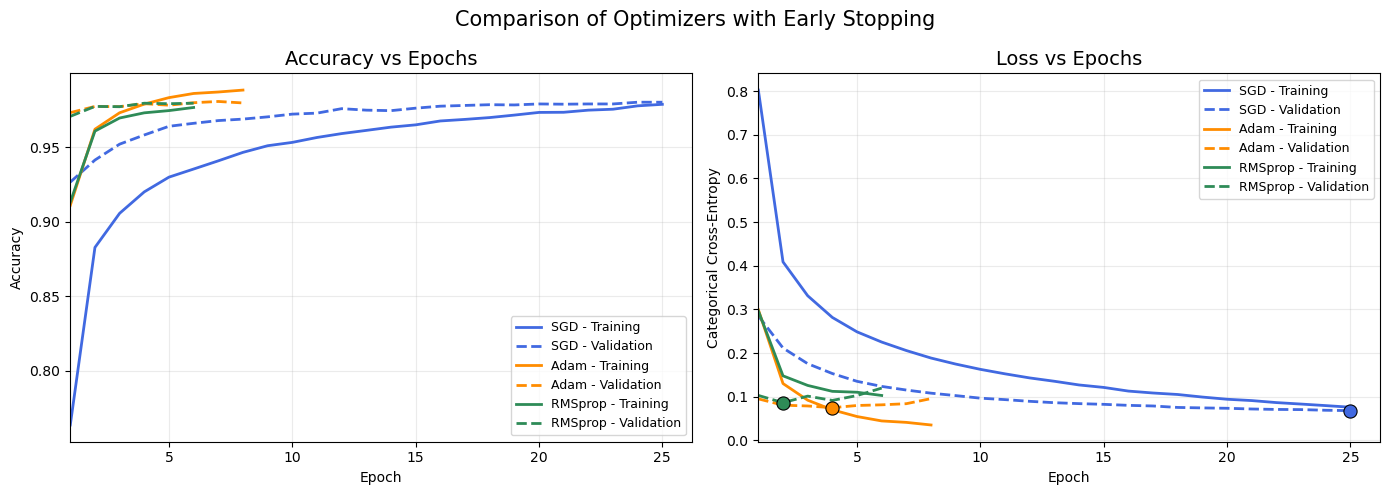

In [13]:
# Colori degli ottimizzatori
colors = {
    "SGD": "royalblue",
    "Adam": "darkorange",
    "RMSprop": "seagreen"
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history in histories.items():

    # Epoche effettivamente eseguite
    ep = np.arange(1, len(history.history["loss"]) + 1)

    # Epoca con validation loss minima
    best_epoch = training_info[name]["best_epoch"]
    best_idx = best_epoch - 1

    # Accuracy di training
    axes[0].plot(
        ep, history.history["accuracy"],
        color=colors[name], linewidth=2,
        label=f"{name} - Training"
    )

    # Accuracy di validation
    axes[0].plot(
        ep, history.history["val_accuracy"],
        color=colors[name], linewidth=2,
        linestyle="--",
        label=f"{name} - Validation"
    )

    # Loss di training
    axes[1].plot(
        ep, history.history["loss"],
        color=colors[name], linewidth=2,
        label=f"{name} - Training"
    )

    # Loss di validation
    axes[1].plot(
        ep, history.history["val_loss"],
        color=colors[name], linewidth=2,
        linestyle="--",
        label=f"{name} - Validation"
    )

    # Evidenziazione della migliore epoca sulla validation loss
    axes[1].scatter(
        best_epoch,
        history.history["val_loss"][best_idx],
        color=colors[name],
        s=90,
        edgecolor="black",
        linewidth=0.8,
        zorder=5
    )

# Impostazioni dei grafici
axes[0].set_title("Accuracy vs Epochs", fontsize=14)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[1].set_title("Loss vs Epochs", fontsize=14)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Categorical Cross-Entropy")

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)
    ax.set_xlim(left=1)

plt.suptitle(
    "Comparison of Optimizers with Early Stopping",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [14]:
# Dizionari per le metriche finali
train_scores = {}
val_scores = {}

for name, model in models.items():

    # Valutazione sul training set
    train_loss, train_acc = model.evaluate(
        X_fit, Y_fit, verbose=0
    )

    # Valutazione sul validation set
    val_loss, val_acc = model.evaluate(
        X_val, Y_val, verbose=0
    )

    train_scores[name] = (train_loss, train_acc)
    val_scores[name] = (val_loss, val_acc)

# Tabella delle prestazioni
print(
    f"{'Optimizer':<10} {'Best Ep.':>9} {'Last Ep.':>9} "
    f"{'Train Acc.':>12} {'Val. Acc.':>12} "
    f"{'Train Loss':>12} {'Val. Loss':>12}"
)

print("-" * 85)

for name in models:

    train_loss, train_acc = train_scores[name]
    val_loss, val_acc = val_scores[name]

    best_ep = training_info[name]["best_epoch"]
    last_ep = training_info[name]["stopped_epoch"]

    print(
        f"{name:<10} {best_ep:>9} {last_ep:>9} "
        f"{train_acc:>12.4f} {val_acc:>12.4f} "
        f"{train_loss:>12.4f} {val_loss:>12.4f}"
    )

Optimizer   Best Ep.  Last Ep.   Train Acc.    Val. Acc.   Train Loss    Val. Loss
-------------------------------------------------------------------------------------
SGD               25        25       0.9876       0.9803       0.0424       0.0680
Adam               4         8       0.9875       0.9793       0.0383       0.0747
RMSprop            2         6       0.9795       0.9775       0.0769       0.0862


In [10]:
# Selezione del modello con validation accuracy maggiore
best_name = max(
    val_scores,
    key=lambda name: (
        val_scores[name][1],
        -val_scores[name][0]
    )
)

# Modello selezionato
model_DNN = models[best_name]

print("Miglior ottimizzatore:", best_name)
print("Migliore epoca:", training_info[best_name]["best_epoch"])

# Valutazione finale sul test set
test_loss, test_accuracy = model_DNN.evaluate(
    X_test, Y_test, verbose=0
)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Miglior ottimizzatore: SGD
Test Loss: 0.0920
Test Accuracy: 0.9720


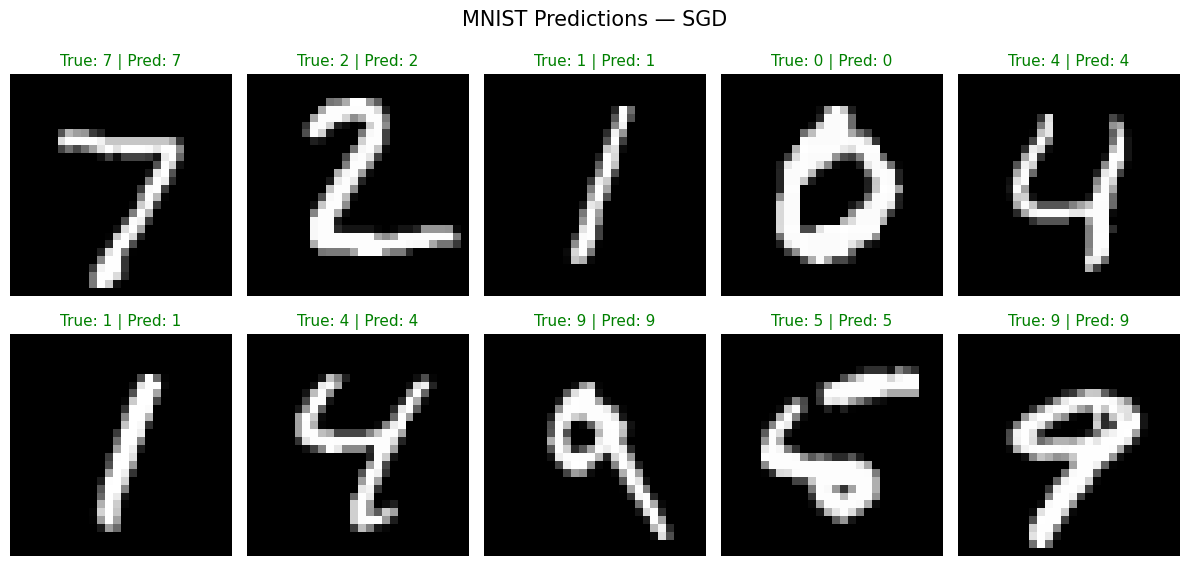

In [15]:
# Predizione delle prime 10 immagini del test set
predictions = model_DNN.predict(X_test[:10], verbose=0)

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):

    # Cifra reale
    true_digit = y_test[i]

    # Cifra predetta dalla rete
    predicted_digit = np.argmax(predictions[i])

    # Visualizzazione dell'immagine
    ax.imshow(X_test_images[i], cmap="gray")

    # Colore del titolo in base alla correttezza
    color = "green" if predicted_digit == true_digit else "red"

    ax.set_title(
        f"True: {true_digit} | Pred: {predicted_digit}",
        color=color,
        fontsize=11
    )

    ax.axis("off")

plt.suptitle(
    f"MNIST Predictions — {best_name}",
    fontsize=15
)

plt.tight_layout()
plt.show()

## 6. Analisi dei risultati e conclusioni

Il confronto tra i tre ottimizzatori evidenzia differenti comportamenti
in termini di velocità di convergenza, accuratezza e capacità di
generalizzazione della rete neurale.

**SGD** presenta una convergenza relativamente lenta, caratterizzata
da una diminuzione progressiva della funzione di costo e da un
miglioramento dell'accuratezza durante tutte le 25 epoche considerate.
Questo ottimizzatore raggiunge la migliore validation accuracy (98.03%)
e la minore validation loss (0.0680). Poiché l'addestramento termina
al numero massimo di epoche senza attivare l'Early Stopping, non
si esclude la possibilità di ottenere ulteriori miglioramenti
prolungando il training.

**Adam** mostra una convergenza sensibilmente più rapida, raggiungendo
il minimo della validation loss alla quarta epoca. Successivamente,
la training loss continua a diminuire, mentre la validation loss
tende ad aumentare, indicando un possibile fenomeno di overfitting.
L'Early Stopping interrompe l'addestramento all'ottava epoca,
ripristinando i pesi corrispondenti alla quarta.

**RMSprop** presenta anch'esso una convergenza iniziale rapida,
raggiungendo il minimo della validation loss già alla seconda epoca.
Tuttavia, le oscillazioni e il successivo peggioramento della
validation loss suggeriscono una minore stabilità della
generalizzazione nella configurazione considerata.
L'addestramento viene interrotto alla sesta epoca.

L'utilizzo dell'**Early Stopping** permette di limitare il rischio
di overfitting, evitando di conservare i pesi ottenuti durante
epoche nelle quali le prestazioni di validation risultano peggiori.

Il modello selezionato utilizza l'ottimizzatore SGD, che presenta
le migliori prestazioni sul validation set. La valutazione finale
su un test set indipendente fornisce:

- **Test accuracy:** 97.20%
- **Test loss:** 0.0920

Si conclude che, nelle condizioni sperimentali considerate,
SGD offre la migliore capacità di generalizzazione sulla validation,
pur richiedendo un numero di epoche superiore rispetto agli
ottimizzatori adattivi.

Il risultato evidenzia inoltre come una convergenza più rapida
non implichi necessariamente prestazioni finali migliori.

# Esercizio 12.2 — Convolutional Neural Network (CNN)

## 1. Introduzione

Nell'esercizio precedente è stata utilizzata una Deep Neural Network
(DNN) per classificare le cifre manoscritte del dataset MNIST.
Le immagini, originariamente rappresentate da matrici di 28×28 pixel,
sono state trasformate in vettori monodimensionali di 784 elementi.

Questa rappresentazione non permette di sfruttare direttamente
la struttura spaziale delle immagini, nella quale pixel vicini
presentano spesso correlazioni significative.

Le **Convolutional Neural Networks (CNN)** consentono invece
di elaborare le immagini mantenendone la struttura bidimensionale,
attraverso l'applicazione di filtri convoluzionali capaci di
identificare caratteristiche locali, come bordi, curve e segmenti.

L'obiettivo dell'esercizio consiste nella costruzione e
nell'addestramento di una CNN per il riconoscimento delle
cifre manoscritte, analizzandone le prestazioni attraverso
l'andamento di accuracy e loss.

I risultati verranno successivamente confrontati con quelli
ottenuti mediante la DNN dell'esercizio 12.1.

Training: (54000, 28, 28, 1)
Validation: (6000, 28, 28, 1)
Test: (10000, 28, 28, 1)


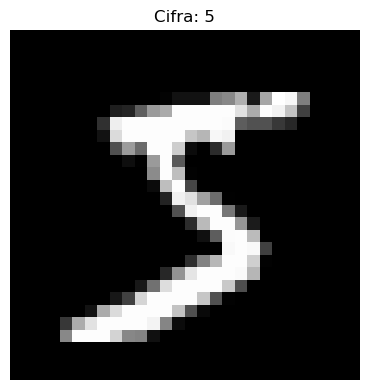

In [16]:
# Dimensioni delle immagini
img_rows, img_cols = 28, 28

# Conversione dei vettori di 784 elementi in immagini 28x28
# L'ultima dimensione rappresenta il singolo canale in scala di grigi
X_fit_cnn = X_fit.reshape(-1, img_rows, img_cols, 1)
X_val_cnn = X_val.reshape(-1, img_rows, img_cols, 1)
X_test_cnn = X_test.reshape(-1, img_rows, img_cols, 1)

# Verifica delle dimensioni dei dataset
print("Training:", X_fit_cnn.shape)
print("Validation:", X_val_cnn.shape)
print("Test:", X_test_cnn.shape)

# Visualizzazione di un'immagine del training set
plt.figure(figsize=(4, 4))

plt.imshow(X_fit_cnn[0, :, :, 0], cmap="gray")
plt.title(f"Cifra: {np.argmax(Y_fit[0])}")
plt.axis("off")

plt.tight_layout()
plt.show()

## 2. Architettura della rete convoluzionale

La rete convoluzionale è costituita da una successione di layer
convoluzionali, di pooling e completamente connessi.

I **layer convoluzionali (Conv2D)** applicano filtri alle immagini
per identificare caratteristiche locali. I filtri vengono traslati
sull'intera immagine utilizzando gli stessi pesi, permettendo
di riconoscere caratteristiche indipendentemente dalla loro
posizione assoluta.

I **layer MaxPooling2D** riducono le dimensioni spaziali delle
mappe di attivazione, conservando il valore massimo all'interno
di regioni locali. Questa operazione riduce il costo computazionale
e introduce una maggiore robustezza rispetto a piccole traslazioni.

Il **Dropout** disattiva casualmente una frazione delle unità
durante l'addestramento, contribuendo a limitare l'overfitting.

Il layer **Flatten** trasforma le mappe bidimensionali in un
vettore monodimensionale, necessario per il successivo
collegamento con i layer Dense.

Infine, il layer di output utilizza la funzione **Softmax**
per assegnare una probabilità a ciascuna delle 10 cifre.

L'architettura adottata comprende:

1. Conv2D: 10 filtri 5×5, attivazione ReLU.
2. MaxPooling2D: finestra 2×2.
3. Conv2D: 20 filtri 3×3, attivazione ReLU.
4. MaxPooling2D: finestra 2×2.
5. Dropout: probabilità 0.25.
6. Flatten.
7. Dense: 100 neuroni, attivazione ReLU.
8. Dropout: probabilità 0.50.
9. Dense: 10 neuroni, attivazione Softmax.

In [17]:
# Funzione per la costruzione della rete convoluzionale
def create_CNN():

    # Creazione del modello sequenziale
    model = keras.Sequential([

        # Layer di input: immagini 28x28 con un canale
        keras.Input(shape=(img_rows, img_cols, 1)),

        # Primo layer convoluzionale: 10 filtri 5x5
        layers.Conv2D(
            10,
            kernel_size=(5, 5),
            activation="relu"
        ),

        # Primo layer di pooling: riduzione delle dimensioni spaziali
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Secondo layer convoluzionale: 20 filtri 3x3
        layers.Conv2D(
            20,
            kernel_size=(3, 3),
            activation="relu"
        ),

        # Secondo layer di pooling
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Dropout per limitare l'overfitting
        layers.Dropout(0.25),

        # Conversione delle mappe di attivazione in un vettore
        layers.Flatten(),

        # Layer completamente connesso
        layers.Dense(100, activation="relu"),

        # Secondo Dropout
        layers.Dropout(0.50),

        # Layer di output: probabilità delle 10 cifre
        layers.Dense(num_classes, activation="softmax")

    ])

    return model


# Creazione della CNN
model_CNN = create_CNN()

# Compilazione del modello
model_CNN.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Visualizzazione dell'architettura
model_CNN.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 24, 24, 10)          │             260 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 12, 12, 10)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 10, 10, 20)          │           1,820 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 20)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 5, 5, 20)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 500)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_21 (Dense)                     │ (None, 100)                 │          50,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_22 (Dense)                     │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 53,190 (207.77 KB)

 Trainable params: 53,190 (207.77 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Addestramento della rete convoluzionale

La rete convoluzionale viene addestrata utilizzando il dataset MNIST,
precedentemente suddiviso in training, validation e test set.

Per mantenere condizioni confrontabili con l'esercizio 12.1,
viene utilizzato l'ottimizzatore **SGD**, con learning rate pari a 0.01.

La funzione di costo adottata è la **categorical cross-entropy**,
appropriata per problemi di classificazione multiclasse:

$$
L=-\frac{1}{N}\sum_{i=1}^{N}\sum_{k=1}^{10}
y_{ik}\log(p_{ik})
$$

dove $y_{ik}$ rappresenta l'etichetta reale e $p_{ik}$ la
probabilità predetta per la classe $k$.

L'addestramento viene effettuato attraverso mini-batch di 32 immagini,
per un massimo di 25 epoche.

Anche in questo caso viene utilizzato l'**Early Stopping**,
monitorando la validation loss con una patience di 4 epoche.

Al termine dell'addestramento vengono ripristinati i pesi
corrispondenti alla minima validation loss osservata.

In [18]:
# Parametri dell'addestramento
batch_size = 32
max_epochs = 25
patience = 4

# Early Stopping basato sulla validation loss
early_stop_CNN = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    min_delta=0.0,
    patience=patience,
    restore_best_weights=True
)

# Addestramento della CNN
history_CNN = model_CNN.fit(
    X_fit_cnn, Y_fit,
    batch_size=batch_size,
    epochs=max_epochs,
    shuffle=True,
    validation_data=(X_val_cnn, Y_val),
    callbacks=[early_stop_CNN],
    verbose=1
)

# Individuazione dell'epoca con la minima validation loss
best_epoch_CNN = np.argmin(
    history_CNN.history["val_loss"]
) + 1

# Numero totale di epoche eseguite
stopped_epoch_CNN = len(history_CNN.history["loss"])

# Risultati dell'addestramento
print("\nAddestramento CNN completato!")
print(f"Epoca migliore: {best_epoch_CNN}")
print(f"Ultima epoca eseguita: {stopped_epoch_CNN}")

print(
    f"Minima validation loss: "
    f"{min(history_CNN.history['val_loss']):.4f}"
)

Epoch 1/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.6537 - loss: 1.0294 - val_accuracy: 0.9535 - val_loss: 0.1787
Epoch 2/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.8899 - loss: 0.3582 - val_accuracy: 0.9710 - val_loss: 0.1053
Epoch 3/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9211 - loss: 0.2590 - val_accuracy: 0.9753 - val_loss: 0.0839
Epoch 4/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.9349 - loss: 0.2143 - val_accuracy: 0.9783 - val_loss: 0.0730
Epoch 5/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 22s 9ms/step - accuracy: 0.9442 - loss: 0.1862 - val_accuracy: 0.9812 - val_loss: 0.0673
Epoch 6/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9497 - loss: 0.1688 - val_accuracy: 0.9825 - val_loss: 0.0639
Epoch 7/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.9528 - loss: 0.1559 - val_accuracy: 0.9825 - val_loss: 0.0585
Epoch 8/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9559 - loss: 0

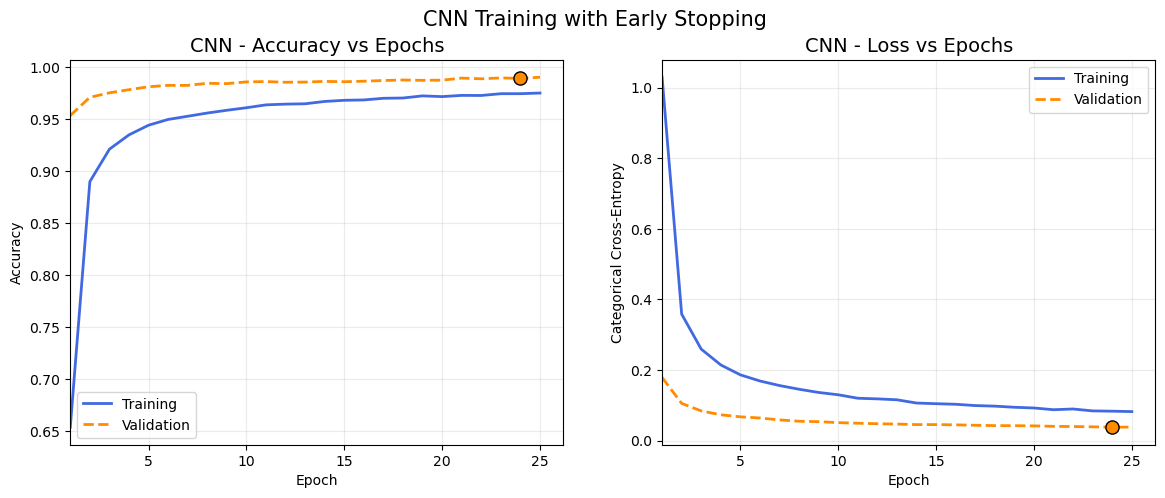

In [23]:
# Epoche effettivamente eseguite
epochs_CNN = np.arange(
    1, len(history_CNN.history["loss"]) + 1
)

# Creazione dei grafici
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafico dell'accuracy
axes[0].plot(
    epochs_CNN,
    history_CNN.history["accuracy"],
    color="royalblue",
    linewidth=2,
    label="Training"
)

axes[0].plot(
    epochs_CNN,
    history_CNN.history["val_accuracy"],
    color="darkorange",
    linewidth=2,
    linestyle="--",
    label="Validation"
)

# Evidenziazione dell'epoca migliore
axes[0].scatter(
    best_epoch_CNN,
    history_CNN.history["val_accuracy"][best_epoch_CNN - 1],
    color="darkorange",
    edgecolor="black",
    s=90,
    zorder=5
)

# Grafico della loss
axes[1].plot(
    epochs_CNN,
    history_CNN.history["loss"],
    color="royalblue",
    linewidth=2,
    label="Training"
)

axes[1].plot(
    epochs_CNN,
    history_CNN.history["val_loss"],
    color="darkorange",
    linewidth=2,
    linestyle="--",
    label="Validation"
)

# Evidenziazione della minima validation loss
axes[1].scatter(
    best_epoch_CNN,
    history_CNN.history["val_loss"][best_epoch_CNN - 1],
    color="darkorange",
    edgecolor="black",
    s=90,
    zorder=5
)

# Personalizzazione dei grafici
axes[0].set_title("CNN - Accuracy vs Epochs", fontsize=14)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[1].set_title("CNN - Loss vs Epochs", fontsize=14)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Categorical Cross-Entropy")

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=10)
    ax.set_xlim(left=1)

plt.suptitle(
    "CNN Training with Early Stopping",
    fontsize=15
)

plt.show()

In [20]:
# Valutazione sul training set
cnn_train_loss, cnn_train_acc = model_CNN.evaluate(
    X_fit_cnn, Y_fit, verbose=0
)

# Valutazione sul validation set
cnn_val_loss, cnn_val_acc = model_CNN.evaluate(
    X_val_cnn, Y_val, verbose=0
)

# Valutazione finale sul test set
cnn_test_loss, cnn_test_acc = model_CNN.evaluate(
    X_test_cnn, Y_test, verbose=0
)

# Stampa dei risultati
print("Prestazioni finali della CNN")
print("-" * 40)

print(f"Training Accuracy:   {cnn_train_acc:.4f}")
print(f"Validation Accuracy: {cnn_val_acc:.4f}")
print(f"Test Accuracy:       {cnn_test_acc:.4f}")

print()

print(f"Training Loss:       {cnn_train_loss:.4f}")
print(f"Validation Loss:     {cnn_val_loss:.4f}")
print(f"Test Loss:           {cnn_test_loss:.4f}")

Prestazioni finali della CNN
----------------------------------------
Training Accuracy:   0.9905
Validation Accuracy: 0.9892
Test Accuracy:       0.9897

Training Loss:       0.0321
Validation Loss:     0.0378
Test Loss:           0.0318


## 5. Confronto tra DNN e CNN

Per valutare l'efficacia dell'architettura convoluzionale,
vengono confrontate le prestazioni della CNN con quelle
della DNN sviluppata nell'esercizio 12.1.

Entrambe le reti utilizzano:

- Lo stesso dataset MNIST.
- La stessa suddivisione in training, validation e test set.
- La funzione di costo categorical cross-entropy.
- L'ottimizzatore SGD, con learning rate pari a 0.01.
- Un massimo di 25 epoche e una batch size di 32.
- Early Stopping con patience pari a 4.

La principale differenza consiste nell'architettura della rete.

La DNN elabora le immagini come vettori monodimensionali,
mentre la CNN conserva la struttura spaziale delle immagini
attraverso layer convoluzionali.

Il confronto viene effettuato considerando il numero di
parametri addestrabili, l'accuracy e la loss sul test set.

In [21]:
# Valutazione della DNN sul test set
dnn_test_loss, dnn_test_acc = model_DNN.evaluate(
    X_test, Y_test, verbose=0
)

# Numero di parametri addestrabili
dnn_params = model_DNN.count_params()
cnn_params = model_CNN.count_params()

# Confronto delle prestazioni
print("Confronto DNN vs CNN")
print("-" * 65)

print(
    f"{'Modello':<12} {'Parametri':>12} "
    f"{'Test Acc.':>15} {'Test Loss':>15}"
)

print("-" * 65)

print(
    f"{'DNN':<12} {dnn_params:>12} "
    f"{dnn_test_acc:>15.4f} {dnn_test_loss:>15.4f}"
)

print(
    f"{'CNN':<12} {cnn_params:>12} "
    f"{cnn_test_acc:>15.4f} {cnn_test_loss:>15.4f}"
)

# Differenza di accuracy tra CNN e DNN
delta_acc = 100 * (cnn_test_acc - dnn_test_acc)

# Riduzione percentuale del numero di parametri
param_reduction = 100 * (1 - cnn_params / dnn_params)

print()
print(f"Differenza di accuracy: {delta_acc:+.2f} punti percentuali")
print(f"Riduzione dei parametri: {param_reduction:.2f}%")

Confronto DNN vs CNN
-----------------------------------------------------------------
Modello         Parametri       Test Acc.       Test Loss
-----------------------------------------------------------------
DNN                355110          0.9720          0.0920
CNN                 53190          0.9897          0.0318

Differenza di accuracy: +1.77 punti percentuali
Riduzione dei parametri: 85.02%


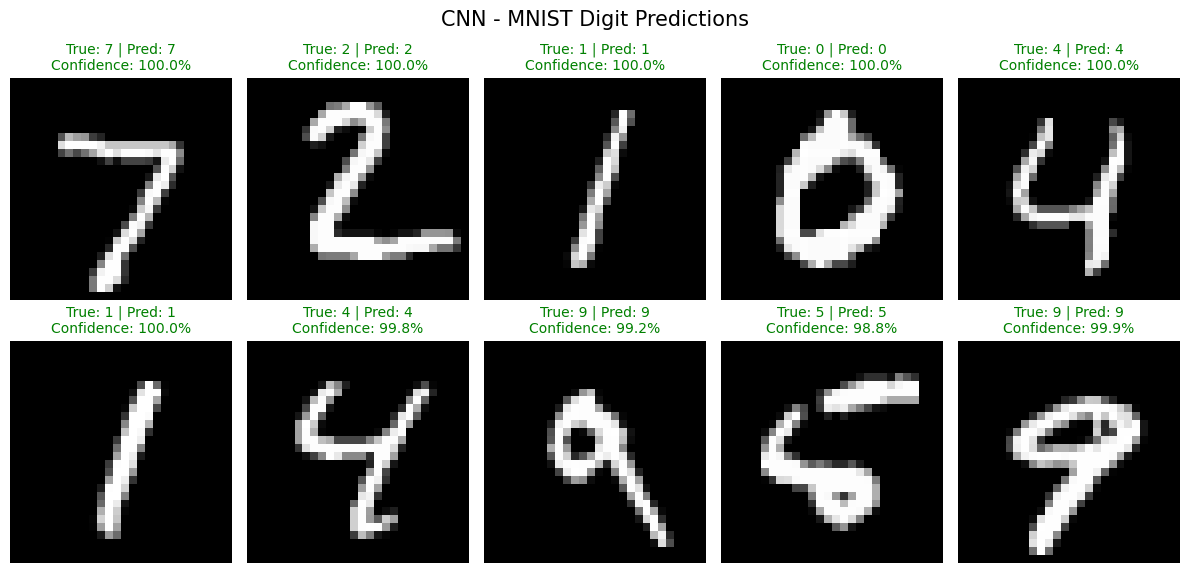

In [22]:
# Predizione delle prime 10 immagini del test set
predictions_CNN = model_CNN.predict(
    X_test_cnn[:10],
    verbose=0
)

# Creazione della figura
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):

    # Etichetta reale
    true_digit = np.argmax(Y_test[i])

    # Cifra predetta dalla CNN
    predicted_digit = np.argmax(predictions_CNN[i])

    # Probabilità assegnata alla classe predetta
    confidence = np.max(predictions_CNN[i]) * 100

    # Visualizzazione della cifra
    ax.imshow(X_test_cnn[i, :, :, 0], cmap="gray")

    # Colore in base alla correttezza della classificazione
    color = "green" if predicted_digit == true_digit else "red"

    ax.set_title(
        f"True: {true_digit} | Pred: {predicted_digit}\n"
        f"Confidence: {confidence:.1f}%",
        color=color,
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "CNN - MNIST Digit Predictions",
    fontsize=15
)

plt.tight_layout()
plt.show()

## 6. Analisi dei risultati e conclusioni

L'addestramento della rete convoluzionale mostra un progressivo
miglioramento delle prestazioni, caratterizzato da un aumento
dell'accuracy e da una diminuzione della loss sia sul training
sia sul validation set.

La rete raggiunge una **validation accuracy del 98.92%** e una
**validation loss di 0.0378**, mostrando una buona capacità di
generalizzazione.

Non si osservano evidenti fenomeni di overfitting, poiché
la validation loss continua complessivamente a diminuire
durante l'addestramento. L'Early Stopping non determina
un'interruzione anticipata, essendo raggiunto il limite
massimo di 25 epoche.

Durante l'addestramento, la validation accuracy risulta
generalmente superiore alla training accuracy. Questo
comportamento è riconducibile principalmente all'utilizzo
del Dropout, attivo durante il training e disattivato
durante la validation.

La valutazione finale sul test set fornisce:

- **Test accuracy:** 98.97%
- **Test loss:** 0.0318

Il confronto con la DNN dell'esercizio 12.1 mostra un
miglioramento significativo delle prestazioni.

La test accuracy passa dal 97.20% della DNN al 98.97%
della CNN, con un incremento di 1.77 punti percentuali.
L'errore di classificazione diminuisce dal 2.80% all'1.03%,
corrispondente a una riduzione relativa di circa il 63%.

Inoltre, il numero di parametri addestrabili diminuisce
da 355110 a 53190, con una riduzione di circa l'85%.

I risultati evidenziano quindi l'efficacia dei layer
convoluzionali nel riconoscimento delle immagini,
grazie alla capacità di sfruttare le correlazioni
spaziali e condividere i pesi dei filtri.

Nelle condizioni sperimentali considerate, la CNN
risulta più accurata della DNN pur utilizzando
un numero significativamente inferiore di parametri.

# Esercizio 12.3 — Riconoscimento di cifre manoscritte

## 1. Introduzione

L'obiettivo dell'esercizio consiste nel verificare la capacità
della Convolutional Neural Network (CNN), precedentemente
addestrata sul dataset MNIST, di riconoscere cifre scritte
manualmente e non appartenenti al dataset originale.

A questo scopo, mediante il programma GIMP, sono state
realizzate 10 immagini corrispondenti alle cifre da 0 a 9.

Ogni immagine è costituita da una matrice di 28×28 pixel
in scala di grigi, con cifra chiara su sfondo nero,
analogamente alle immagini utilizzate durante il training.

Le immagini vengono importate, normalizzate nell'intervallo
[0,1] e successivamente fornite alla CNN, senza modificare
i pesi precedentemente addestrati.

Le prestazioni vengono valutate confrontando le cifre
reali con quelle predette dalla rete e analizzando
le probabilità associate alle diverse classificazioni.

In [24]:
from pathlib import Path
from PIL import Image

# Cartella contenente le cifre disegnate manualmente
folder = Path("PNG")

# Liste per memorizzare le immagini e le etichette
handwritten_images = []
handwritten_labels = []

# Caricamento delle cifre da 0 a 9
for digit in range(10):

    # Percorso dell'immagine
    filename = folder / f"{digit}.png"

    # Verifica dell'esistenza del file
    if not filename.is_file():
        raise FileNotFoundError(f"File non trovato: {filename}")

    # Apertura e conversione in scala di grigi
    with Image.open(filename) as image:
        image = image.convert("L")

        # Verifica delle dimensioni
        if image.size != (28, 28):
            raise ValueError(
                f"L'immagine {filename} non ha dimensioni 28x28."
            )

        # Conversione in array e normalizzazione
        data = np.asarray(image, dtype="float32") / 255.0

    # Memorizzazione dell'immagine e della cifra reale
    handwritten_images.append(data)
    handwritten_labels.append(digit)

# Conversione delle liste in array NumPy
handwritten_images = np.array(handwritten_images)
handwritten_labels = np.array(handwritten_labels)

# Verifica delle dimensioni
print("Dimensioni immagini:", handwritten_images.shape)
print("Dimensioni etichette:", handwritten_labels.shape)
print("Intervallo pixel:",
      handwritten_images.min(),
      handwritten_images.max())

Dimensioni immagini: (10, 28, 28)
Dimensioni etichette: (10,)
Intervallo pixel: 0.0 1.0


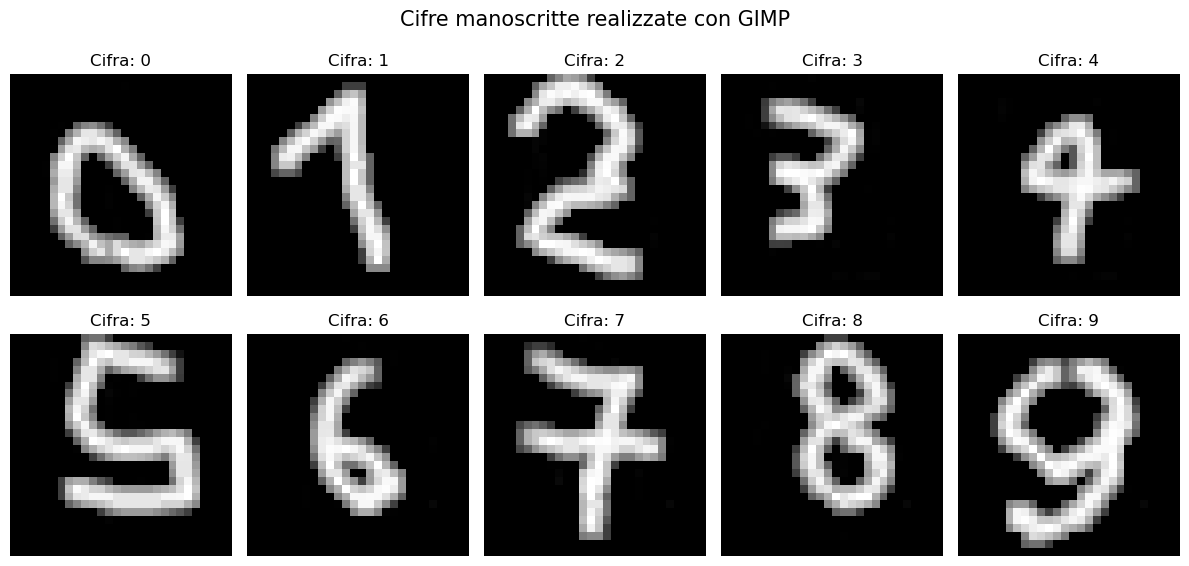

In [25]:
# Creazione della figura
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):

    # Visualizzazione dell'immagine
    ax.imshow(
        handwritten_images[i],
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    # Etichetta della cifra originale
    ax.set_title(
        f"Cifra: {handwritten_labels[i]}",
        fontsize=12
    )

    ax.axis("off")

plt.suptitle(
    "Cifre manoscritte realizzate con GIMP",
    fontsize=15
)

plt.tight_layout()
plt.show()

## 2. Preprocessing e classificazione

Le immagini importate vengono convertite in una rappresentazione
compatibile con l'architettura della CNN.

Poiché la rete è stata addestrata utilizzando immagini di
dimensioni 28×28 con un singolo canale, l'input deve avere
la forma:

$$
(N,28,28,1)
$$

dove $N=10$ rappresenta il numero di immagini da classificare.

I valori dei pixel sono già stati normalizzati dividendo
le intensità originali per 255, ottenendo valori compresi
nell'intervallo [0,1].

La classificazione viene effettuata mediante il modello
precedentemente addestrato, senza alcun ulteriore
aggiornamento dei pesi.

Il layer finale Softmax restituisce, per ciascuna immagine,
un vettore di 10 probabilità:

$$
\mathbf{p}=(p_0,p_1,\ldots,p_9)
$$

La cifra predetta corrisponde alla classe associata
alla probabilità massima:

$$
\hat{y}=\operatorname{argmax}_k(p_k)
$$

La probabilità massima viene inoltre utilizzata come
indicatore della confidenza della predizione, pur non
rappresentando necessariamente una probabilità calibrata
di correttezza.

In [26]:
# Aggiunta della dimensione relativa al canale
handwritten_images_cnn = handwritten_images.reshape(
    -1, img_rows, img_cols, 1
)

# Verifica della forma degli input
print("Input CNN:", handwritten_images_cnn.shape)

# Predizione delle cifre manoscritte
predictions_handwritten = model_CNN.predict(
    handwritten_images_cnn,
    verbose=0
)

# Cifre predette dalla rete
predicted_digits = np.argmax(
    predictions_handwritten,
    axis=1
)

# Probabilità massima di ogni predizione
confidence = np.max(
    predictions_handwritten,
    axis=1
)

# Verifica delle classificazioni
correct_predictions = predicted_digits == handwritten_labels

print("\nPredizioni completate!")
print("Cifre reali:    ", handwritten_labels)
print("Cifre predette: ", predicted_digits)

Input CNN: (10, 28, 28, 1)

Predizioni completate!
Cifre reali:     [0 1 2 3 4 5 6 7 8 9]
Cifre predette:  [0 1 2 3 4 5 6 7 8 9]


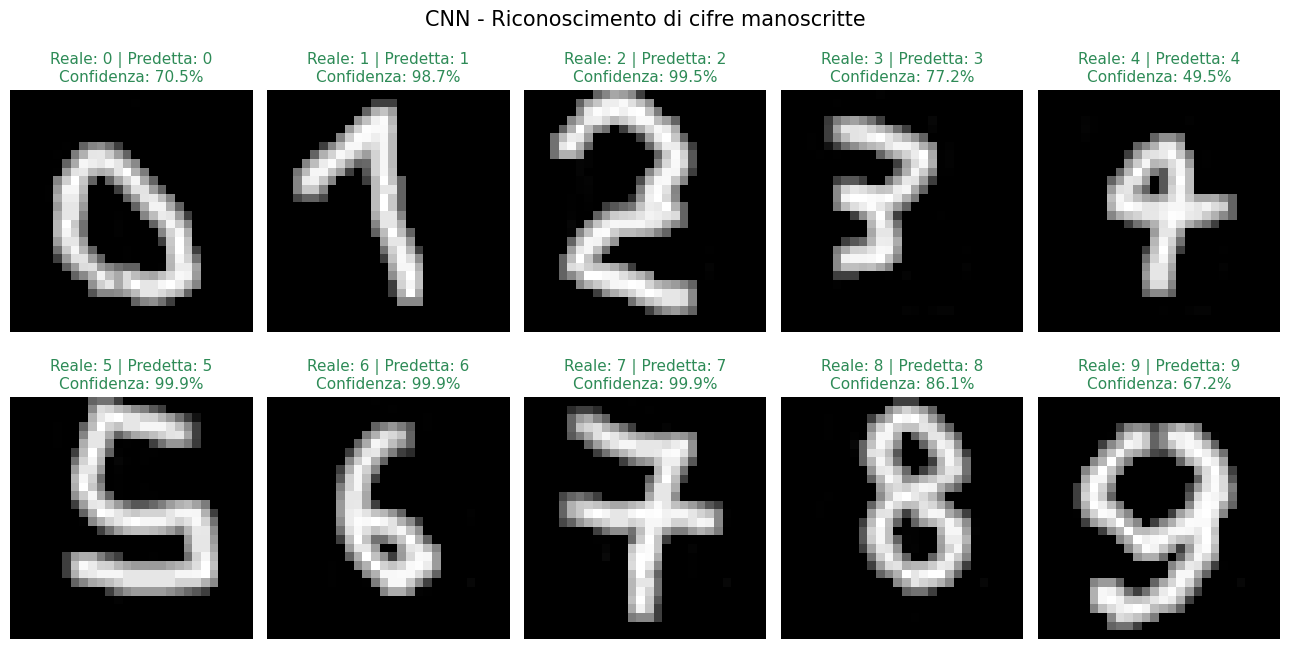

In [27]:
# Creazione della figura
fig, axes = plt.subplots(2, 5, figsize=(13, 7))

for i, ax in enumerate(axes.flat):

    # Cifra reale e cifra predetta
    true_digit = handwritten_labels[i]
    predicted_digit = predicted_digits[i]

    # Probabilità della classe predetta
    probability = confidence[i] * 100

    # Colore in base alla correttezza della classificazione
    color = "seagreen" if correct_predictions[i] else "crimson"

    # Visualizzazione dell'immagine
    ax.imshow(
        handwritten_images[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    # Titolo con risultato della classificazione
    ax.set_title(
        f"Reale: {true_digit} | Predetta: {predicted_digit}\n"
        f"Confidenza: {probability:.1f}%",
        color=color,
        fontsize=11
    )

    ax.axis("off")

plt.suptitle(
    "CNN - Riconoscimento di cifre manoscritte",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [28]:
# Numero di classificazioni corrette
n_correct = np.sum(correct_predictions)

# Numero totale di immagini
n_total = len(handwritten_labels)

# Accuracy sulle cifre disegnate
handwritten_accuracy = n_correct / n_total

# Intestazione della tabella
print(
    f"{'Cifra reale':<14}"
    f"{'Predizione':<14}"
    f"{'Confidenza':<14}"
    f"{'Esito':<12}"
)

print("-" * 54)

# Risultati per ogni cifra
for i in range(n_total):

    result = "Corretta" if correct_predictions[i] else "Errata"

    print(
        f"{handwritten_labels[i]:<14}"
        f"{predicted_digits[i]:<14}"
        f"{confidence[i] * 100:<13.2f}%"
        f"{result:<12}"
    )

# Riepilogo finale
print("\n" + "-" * 54)
print(f"Classificazioni corrette: {n_correct}/{n_total}")
print(f"Accuracy: {handwritten_accuracy * 100:.2f}%")

Cifra reale   Predizione    Confidenza    Esito       
------------------------------------------------------
0             0             70.47        %Corretta    
1             1             98.69        %Corretta    
2             2             99.47        %Corretta    
3             3             77.22        %Corretta    
4             4             49.46        %Corretta    
5             5             99.93        %Corretta    
6             6             99.90        %Corretta    
7             7             99.94        %Corretta    
8             8             86.08        %Corretta    
9             9             67.15        %Corretta    

------------------------------------------------------
Classificazioni corrette: 10/10
Accuracy: 100.00%


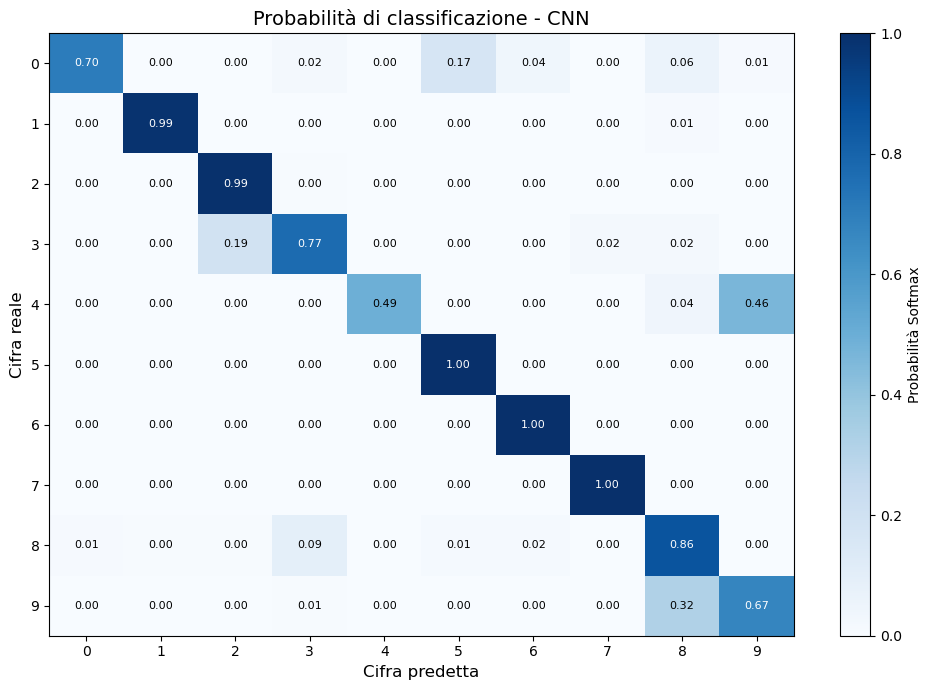

In [29]:
# Creazione della matrice delle probabilità
fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(
    predictions_handwritten,
    cmap="Blues",
    vmin=0,
    vmax=1,
    aspect="auto"
)

# Etichette degli assi
ax.set_xticks(np.arange(10))
ax.set_yticks(np.arange(10))

ax.set_xticklabels(np.arange(10))
ax.set_yticklabels(handwritten_labels)

ax.set_xlabel("Cifra predetta", fontsize=12)
ax.set_ylabel("Cifra reale", fontsize=12)

ax.set_title(
    "Probabilità di classificazione - CNN",
    fontsize=14
)

# Valori delle probabilità all'interno delle celle
for i in range(10):
    for j in range(10):

        value = predictions_handwritten[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value > 0.5 else "black"
        )

# Barra dei colori
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Probabilità Softmax")

plt.tight_layout()
plt.show()


## 4. Analisi dei risultati e conclusioni

L'applicazione della CNN alle 10 cifre manoscritte realizzate con GIMP ha prodotto una classificazione corretta di tutte le immagini, raggiungendo un'**accuracy del 100%** sul campione considerato.

L'analisi della matrice delle probabilità mostra una prevalenza dei valori lungo la diagonale principale, confermando la corrispondenza tra le cifre reali e quelle predette.

Il risultato ottenuto mostra che la CNN è in grado di riconoscere anche immagini manoscritte esterne al dataset MNIST, senza necessità di un ulteriore addestramento.

